# E-commerce Funnel Analysis Using Python

Funnel analysis is a data analysis technique used to understand the journey users take while interacting with a website, from their initial visit to completing a desired action, such as making a purchase.

This project analyses user journey data to understand how users progress through different stages of the e-commerce funnel: **Browse, Add to Cart, Checkout, and Purchase**. Using Python, the analysis aims to identify where users drop off, evaluate conversion rates at each stage, and explore how factors such as device type, marketing channel, region, and product category relate to user behaviour and purchase outcomes.

The findings can help identify potential areas for improvement in the user journey and support data-driven decisions to improve conversion performance.

Importing all libraries at the beginning ensures consistency and avoids repetition later in the notebook.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

###### The required Python libraries are imported for data manipulation and visualisation.

###### Pandas: Used for loading, cleaning, manipulating and analysing the dataset.

###### Matplotlib: Used for creating charts and visualisations.

###### Seaborn: Used for creating statistical visualisations.

###### Plotly: Used for creating interactive charts and visualisations.

# Loading the dataset

Loading the dataset Funnel_Analysis_Data.csv into a Pandas DataFrame named df.

In [2]:
df = pd.read_csv("Funnel_Analysis_Data.csv")

Checking the number of rows and columns

In [3]:
df.shape 

(21409, 10)

###### The dataset contains 21,409 rows and 10 columns. Each row represents an event recorded during a user's shopping session.

Displaying the first 5 and last 5 rows using head() and tail()

In [4]:
df.head()

,User ID,Session ID,Event Time,Event,Device,Region,Channel,Product Category,Revenue,Bonus Flag
0,USR-00001,SES-00001,2026-01-07 23:46:20.358501,Browse,Tablet,South,Organic,Electronics,0.0,Yes
1,USR-00001,SES-00001,2026-01-07 23:49:20.358501,Add to Cart,Tablet,South,Organic,Electronics,0.0,Yes
2,USR-00001,SES-00001,2026-01-07 23:51:20.358501,Checkout,Tablet,South,Organic,Electronics,0.0,Yes
3,USR-00002,SES-00002,2026-01-04 21:06:42.296010,Browse,Desktop,East,Email,Sports,0.0,Yes
4,USR-00002,SES-00002,2026-01-04 21:10:42.296010,Add to Cart,Desktop,East,Email,Sports,0.0,Yes


In [5]:
df.tail()

,User ID,Session ID,Event Time,Event,Device,Region,Channel,Product Category,Revenue,Bonus Flag
21404,USR-09997,SES-09997,2026-01-03 14:01:06.074656,Checkout,Mobile,North,Google Ads,Sports,0.0,Yes
21405,USR-09998,SES-09998,2025-12-17 06:17:57.577958,Browse,Desktop,North,Social Media,Beauty,0.0,Yes
21406,USR-09998,SES-09998,2025-12-17 06:22:57.577958,Add to Cart,Desktop,North,Social Media,Beauty,0.0,Yes
21407,USR-09999,SES-09999,2025-12-30 15:47:23.983289,Browse,Mobile,East,Email,Sports,0.0,Yes
21408,USR-10000,SES-10000,2025-12-19 18:57:10.591617,Browse,Tablet,East,Email,Beauty,0.0,Yes


Finding the column names

In [6]:
df.columns

Index(['User ID', 'Session ID', 'Event Time', 'Event', 'Device', 'Region',
       'Channel', 'Product Category', 'Revenue', 'Bonus Flag'],
      dtype='str')

###### User ID and Session ID to identify users and their sessions.

###### Event Time to identify when an action occurred.

###### Event to identify the action performed.

###### Device, Region and Channel to understand user characteristics and traffic sources.

###### Product Category and Revenue to understand product and purchase information.

###### Bonus Flag could indicate bonus incentive.

Collecting more information about the dataset using info().

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21409 entries, 0 to 21408
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User ID           21409 non-null  str    
 1   Session ID        21409 non-null  str    
 2   Event Time        21409 non-null  str    
 3   Event             21409 non-null  str    
 4   Device            21409 non-null  str    
 5   Region            21409 non-null  str    
 6   Channel           21409 non-null  str    
 7   Product Category  21409 non-null  str    
 8   Revenue           21409 non-null  float64
 9   Bonus Flag        21409 non-null  str    
dtypes: float64(1), str(9)
memory usage: 3.3 MB


###### The result tells us that there are 21409 rows and 10 columns and the name of each column  with the data type. It also tells whether there are any null values present. 

###### According to this data, the data type of Event Time is incorrect. There seems to be no null values


# Data Cleaning

Checking for missing values

In [8]:
df.isnull().sum()

User ID             0
Session ID          0
Event Time          0
Event               0
Device              0
Region              0
Channel             0
Product Category    0
Revenue             0
Bonus Flag          0
dtype: int64

###### Now in this case there are no missing values
###### If it were to be there use appropriate method
###### to drop the row that has null values use
###### df.dropna() 
###### It will return a new DataFrame, and will not change the original. If changes is to be made to the original DataFrame use 
###### df.dropna(inplace=True) 
###### If we want to replace empty cells with a values use fillna()
###### df.fillna({"Revenue":250})
###### In case we want to replace empty cell with mean
###### x= df["Revenue"].mean()
###### df.fillna({"Revenue":x},inplace=True)
###### similarly we can fill using mode or median

In [9]:
df.duplicated().sum()

np.int64(0)

Deleting duplicate values

In [10]:
df.drop_duplicates(inplace = True)

Checking the data types

In [11]:
df.dtypes

User ID                 str
Session ID              str
Event Time              str
Event                   str
Device                  str
Region                  str
Channel                 str
Product Category        str
Revenue             float64
Bonus Flag              str
dtype: object

###### Event Time has incorrect data type. It needs to be converted into datetime format.

In [12]:
df["Event Time"]=pd.to_datetime(df["Event Time"],errors="coerce")

In [13]:
df.dtypes

User ID                        str
Session ID                     str
Event Time          datetime64[us]
Event                          str
Device                         str
Region                         str
Channel                        str
Product Category               str
Revenue                    float64
Bonus Flag                     str
dtype: object

###### Event Time is successfully converted

Checking whether any timestamps failed to convert

In [14]:
df["Event Time"].isnull().sum()

np.int64(0)

###### All values in Event Time is converted.

In [15]:
print("Missing Revenue",df["Revenue"].isnull().sum())
print("Negative Revenue",(df["Revenue"]<0).sum())
print("Zero Revenue",(df["Revenue"]==0).sum())


Missing Revenue 0
Negative Revenue 0
Zero Revenue 20405


In [16]:
print("Earliest date",(df["Event Time"].min()))
print("Latest date",(df["Event Time"].max()))

Earliest date 2025-12-09 15:42:28.549392
Latest date 2026-01-08 15:38:33.842791


In [17]:
tcol=["Event","Device","Region","Channel","Product Category"]
for i in tcol:
    df[i]=df[i].str.title().str.strip()

Finding unique values in each column and thier count

In [18]:
for i in ['Event', 'Device', 'Region','Channel', 'Product Category','Bonus Flag']:
      print(df[i].value_counts())

Event
Browse         10000
Add To Cart     6949
Checkout        3456
Purchase        1004
Name: count, dtype: int64
Device
Desktop    7271
Tablet     7190
Mobile     6948
Name: count, dtype: int64
Region
South    5466
East     5397
West     5278
North    5268
Name: count, dtype: int64
Channel
Google Ads      5427
Email           5404
Organic         5378
Social Media    5200
Name: count, dtype: int64
Product Category
Electronics    4435
Beauty         4353
Fashion        4289
Home           4185
Sports         4147
Name: count, dtype: int64
Bonus Flag
Yes    20405
No      1004
Name: count, dtype: int64


###### This helps you identify inconsistent spelling, unexpected categories, or extra spaces.
###### The counts give us an initial view of how many records belong to each funnel stage.

In [19]:
df.describe()

,Event Time,Revenue
count,21409,21409.000000
mean,2025-12-24 17:37:47.235691,12.953574
min,2025-12-09 15:42:28.549392,0.000000
25%,2025-12-17 05:28:25.527814,0.000000
50%,2025-12-24 19:59:47.237094,0.000000
75%,2026-01-01 06:24:53.551130,0.000000
max,2026-01-08 15:38:33.842791,499.990000
std,NaN,65.005620


###### Initial Observations from Numerical and Date Columns

###### The dataset contains 21,409 event records with no missing values in the displayed columns.
###### Event timestamps range from 9 December 2025 to 8 January 2026.
###### Revenue ranges from 0 to 499.99.
###### The mean revenue per event record is approximately 12.95.
###### The median revenue is 0, indicating that at least half of the event records have zero revenue.
###### Further investigation is required to understand revenue distribution across different funnel stages.

Unique users and sessions

In [20]:
print("Unique users",(df["User ID"].nunique()))
print("Unique sessions",(df["Session ID"].nunique()))

Unique users 10000
Unique sessions 10000


Check the event sequence

In [21]:
df=df.sort_values(["Session ID", "Event Time"])
sequence = df.groupby("Session ID")["Event"].apply(">".join)
sequence.value_counts()

Event
Browse>Add To Cart                      3493
Browse                                  3051
Browse>Add To Cart>Checkout             2452
Browse>Add To Cart>Checkout>Purchase    1004
Name: count, dtype: int64

Investigating Bonus flag

In [22]:
df.groupby("Bonus Flag")["Event"].value_counts()

Bonus Flag  Event      
No          Purchase        1004
Yes         Browse         10000
            Add To Cart     6949
            Checkout        3456
Name: count, dtype: int64

###### All Browse, Add to Cart and Checkout events have Bonus Flag = Yes.
###### All Purchase events have Bonus Flag = No.

# Exploratory Data Analysis

## 1. Overall Funnel Performance
This analysis examines how users progress through the e-commerce shopping journey, from browsing products to completing a purchase. It measures the number of users at each stage and calculates conversion and drop-off rates between consecutive stages to identify where users are most likely to leave the funnel.

The following calculation counts the recorded events at each stage of the shopping funnel. This provides an overview of how many users progressed through each step.

In [23]:
event_counts = df["Event"].value_counts()
event_counts

Event
Browse         10000
Add To Cart     6949
Checkout        3456
Purchase        1004
Name: count, dtype: int64

The event counts show a decrease in activity as users move through the funnel. To understand this progression more clearly, conversion and drop-off rates are calculated between each consecutive stage.

In [24]:
stages=["Browse","Add To Cart","Checkout","Purchase"]
for i in range((len(stages)-1)):
    cur = event_counts[stages[i]]
    nex = event_counts[stages[i+1]]
    conv = (nex/cur)*100
    drop = 100-conv
    print(stages[i], "to", stages[i + 1])
    print("Conversion Rate:", round(conv, 2), "%")
    print("Drop-off Rate:", round(drop, 2), "%")
    print()

Browse to Add To Cart
Conversion Rate: 69.49 %
Drop-off Rate: 30.51 %

Add To Cart to Checkout
Conversion Rate: 49.73 %
Drop-off Rate: 50.27 %

Checkout to Purchase
Conversion Rate: 29.05 %
Drop-off Rate: 70.95 %



The funnel analysis shows that 10,000 users browsed the website, while 6,949 added products to their cart, 3,456 reached checkout and 1,004 completed purchases.

The conversion rate decreases at each stage of the funnel.

The results show that:
- Browse to Add to Cart: 69.49% conversion and 30.51% drop-off.
- Add to Cart to Checkout: 49.73% conversion and 50.27% drop-off.
- Checkout to Purchase: 29.05% conversion and 70.95% drop-off.
The highest drop-off occurs between Checkout and Purchase. This indicates that a significant proportion of users who reach checkout do not complete their purchases. Further investigation is needed to identify the reasons for this abandonment.

## 2. Marketing Channel Performance
This analysis compares the performance of Google Ads, Email, Organic and Social Media channels. It examines user acquisition, purchasing users, conversion rates and purchase revenue to understand which channels attract users and contribute most effectively to sales.

The event count for each channel shows how shopping activity is distributed across the different marketing sources.

In [27]:
df["Channel"].value_counts()

Channel
Google Ads      5427
Email           5404
Organic         5378
Social Media    5200
Name: count, dtype: int64

The event counts are relatively similar across all four channels, indicating a balanced distribution of recorded activity.

This calculation identifies the number of distinct users associated with each marketing channel, providing a clearer comparison of audience reach.

In [28]:
total_users=df.groupby("Channel")["User ID"].nunique()
total_users

Channel
Email           2515
Google Ads      2520
Organic         2528
Social Media    2437
Name: User ID, dtype: int64

The following calculation counts the unique users who completed a purchase through each channel.

In [29]:
purchase_user = df[df["Event"]=="Purchase"].groupby("Channel")["User ID"].nunique()
purchase_user

Channel
Email           248
Google Ads      268
Organic         239
Social Media    249
Name: User ID, dtype: int64

The purchase conversion rate is calculated by dividing the number of purchasing users by the total unique users in each channel. This helps compare how effectively each channel converts its audience into customers.

In [30]:
conversion=round((purchase_user/total_users)*100,2)
conversion.sort_values(ascending=False)

Channel
Google Ads      10.63
Social Media    10.22
Email            9.86
Organic          9.45
Name: User ID, dtype: float64

Google Ads has the highest purchase conversion rate at 10.63%, followed by Social Media at 10.22%, Email at 9.86% and Organic at 9.45%.

This suggests that Google Ads converts its audience more effectively than the other channels in this dataset.

Purchase revenue is grouped by marketing channel to identify which channel contributes the highest total sales revenue. Only Purchase events are considered in this calculation.

In [31]:
#crevenue=df.groupby("Channel")["Revenue"].sum().sort_values(ascending=False)
crevenue=df[df["Event"]=="Purchase"].groupby("Channel")["Revenue"].sum().sort_values(ascending=False)
crevenue

Channel
Google Ads      73862.32
Email           69126.46
Social Media    68361.24
Organic         65973.04
Name: Revenue, dtype: float64

Google Ads generates the highest purchase revenue of 73,862.32, followed by Email at 69,126.46, Social Media at 68,361.24 and Organic at 65,973.04.

In [32]:
channel_analysis = pd.DataFrame(
    {
        "Total Users ":total_users,
        "Purchasing Users": purchase_user,
        "Conversion Rate(%)": conversion,
        "Revenue": crevenue
    }
)
channel_analysis.sort_values("Conversion Rate(%)",ascending=False)
    

,Total Users,Purchasing Users,Conversion Rate(%),Revenue
Channel,,,,
Google Ads,2520,268,10.63,73862.32
Social Media,2437,249,10.22,68361.24
Email,2515,248,9.86,69126.46
Organic,2528,239,9.45,65973.04


Overall, Google Ads performs best in both purchase conversion rate and total purchase revenue. Organic attracts the highest number of unique users, but has the lowest conversion rate among the four channels.

## 3. Device Performance
This analysis compares user activity and purchasing behaviour across Desktop, Tablet and Mobile devices. It examines the number of users, completed purchases, conversion rates, drop-off rates and purchase revenue to identify differences in performance across devices.

The event count shows how shopping activity is distributed across the three device types.

In [36]:
 df["Device"].value_counts()

Device
Desktop    7271
Tablet     7190
Mobile     6948
Name: count, dtype: int64

This calculation identifies the number of distinct users accessing the website through each device.

In [37]:
t=df.groupby("Device")["User ID"].nunique().sort_values(ascending=False)
t

Device
Tablet     3371
Desktop    3366
Mobile     3263
Name: User ID, dtype: int64

The following calculation counts the users who completed a purchase on each device.

In [38]:
p = df[df["Event"]=="Purchase"]["Device"].value_counts()
p.sort_values(ascending=False)

Device
Desktop    356
Tablet     339
Mobile     309
Name: count, dtype: int64

The purchase conversion rate measures the percentage of users on each device who completed a purchase. The drop-off rate represents the remaining percentage who did not complete a purchase.

Purchase Conversion Rate

In [39]:
c1=round((p/t)*100,2)
c1.sort_values(ascending = False)

Device
Desktop    10.58
Tablet     10.06
Mobile      9.47
dtype: float64

Drop-off Rate

In [40]:
d1=100-c1
d1

Device
Desktop    89.42
Mobile     90.53
Tablet     89.94
dtype: float64

Desktop has the highest purchase conversion rate at 10.58%, followed by Tablet at 10.06% and Mobile at 9.47%.

Mobile has the highest drop-off rate at 90.53%, while Desktop has the lowest at 89.42%. This indicates that Mobile users convert at a lower rate than users on the other two devices.

Purchase revenue is grouped by device to compare the total sales contribution from Desktop, Tablet and Mobile users.

In [41]:
#r1=df.groupby("Device")["Revenue"].sum()
r1=df[df["Event"]=="Purchase"].groupby("Device")["Revenue"].sum()
r1.sort_values(ascending=False)

Device
Desktop    98471.83
Tablet     94620.13
Mobile     84231.10
Name: Revenue, dtype: float64

Desktop generates the highest purchase revenue at 98,471.83, followed by Tablet at 94,620.13 and Mobile at 84,231.10.

In [42]:
device_analysis=pd.DataFrame(
    {
        "Total Users":t,
        "Purchasing Users":p,
        "Conversion Rate (%)":c1,
        "Drop off (%)":d1,
        "Revenue":r1
        
    }
)
device_analysis.sort_values("Conversion Rate (%)",ascending=False)

,Total Users,Purchasing Users,Conversion Rate (%),Drop off (%),Revenue
Device,,,,,
Desktop,3366,356,10.58,89.42,98471.83
Tablet,3371,339,10.06,89.94,94620.13
Mobile,3263,309,9.47,90.53,84231.10


Overall, Desktop performs best in both conversion rate and total revenue. Mobile has the lowest conversion rate and revenue, suggesting that its shopping experience may require further investigation.

## 4. Regional Performance
This analysis compares e-commerce activity across the North, South, East and West regions. It examines user distribution, purchasing customers, conversion rates and purchase revenue to identify regional differences in customer behaviour and sales performance.

The event count provides an overview of recorded shopping activity across the four regions.

In [45]:
df["Region"].value_counts()

Region
South    5466
East     5397
West     5278
North    5268
Name: count, dtype: int64

In [46]:
t2=df.groupby("Region")["User ID"].nunique()
t2.sort_values(ascending = False)

Region
East     2548
South    2543
North    2463
West     2446
Name: User ID, dtype: int64

The following calculation counts the unique customers who completed purchases in each region.

In [47]:
p2 = df[df["Event"]=="Purchase"].groupby("Region")["User ID"].nunique()
p2.sort_values(ascending=False)
#p2=df[df["Event"]=="Purchase"]["Region"].value_counts()
#p2.sort_values(ascending=False)

Region
South    268
North    253
East     245
West     238
Name: User ID, dtype: int64

The purchase conversion rate is calculated by comparing purchasing customers with the total unique users in each region. This helps identify which region converts its audience most effectively.

In [48]:
c2=round((p2/t2)*100,2)
c2.sort_values(ascending = False)

Region
South    10.54
North    10.27
West      9.73
East      9.62
Name: User ID, dtype: float64

South has the highest purchase conversion rate at 10.54%, followed by North at 10.27%, West at 9.73% and East at 9.62%.

Although East has the highest number of unique users, South converts a larger proportion of its audience into purchasing customers.

Purchase revenue is grouped by region to identify which geographical area contributes the most to total sales.

In [49]:
#r2=df.groupby("Region")["Revenue"].sum()
r2=df[df["Event"]=="Purchase"].groupby("Region")["Revenue"].sum()
r2.sort_values(ascending = False)

Region
South    77421.45
North    68645.13
East     66116.01
West     65140.47
Name: Revenue, dtype: float64

South generates the highest purchase revenue at 77,421.45, followed by North at 68,645.13, East at 66,116.01 and West at 65,140.47.

In [50]:
regional_analysis= pd.DataFrame(
    {
        "Total Users":t2,
        "Purchasing Users":p2,
        "Conversion Rate(%)":c2,
        "Revenue":r2
    }
)
regional_analysis.sort_values("Conversion Rate(%)",ascending=False)

,Total Users,Purchasing Users,Conversion Rate(%),Revenue
Region,,,,
South,2543,268,10.54,77421.45
North,2463,253,10.27,68645.13
West,2446,238,9.73,65140.47
East,2548,245,9.62,66116.01


Overall, South performs best in both purchase conversion rate and total revenue, while East has the largest user base but the lowest conversion rate.

## 5. Product Category Performance
This analysis examines shopping activity and sales performance across Electronics, Beauty, Fashion, Home and Sports categories. It compares category distribution, purchase counts, revenue contribution and average purchase value to identify the strongest-performing product categories.

The following calculation counts the recorded events associated with each product category. This provides an overview of user activity across the available categories.

In [53]:
category_distribution=df["Product Category"].value_counts()
category_distribution.sort_values(ascending=False)

Product Category
Electronics    4435
Beauty         4353
Fashion        4289
Home           4185
Sports         4147
Name: count, dtype: int64

Category Distribution (%)

In [54]:
total=len(df)
distribution_percent=round((category_distribution/total)*100,2)
distribution_percent.sort_values(ascending=False)

Product Category
Electronics    20.72
Beauty         20.33
Fashion        20.03
Home           19.55
Sports         19.37
Name: count, dtype: float64

Electronics has the highest recorded activity, accounting for 4,435 events (20.72% of all events). Sports has the lowest, with 4,147 events (19.37%). The distribution is relatively balanced across all five categories

This calculation counts completed purchases in each product category to identify which categories generate the highest purchase volume.

In [55]:
p3=df[df["Event"]=="Purchase"]["Product Category"].value_counts()
p3.sort_values(ascending = False)

Product Category
Electronics    229
Fashion        211
Beauty         191
Sports         189
Home           184
Name: count, dtype: int64

The percentage contribution shows how much each category contributes to the total number of completed purchases.

In [56]:
sum_pc=p3.sum()
purchase_percentage=round((p3/sum_pc)*100,2)
purchase_percentage.sort_values(ascending=False)

Product Category
Electronics    22.81
Fashion        21.02
Beauty         19.02
Sports         18.82
Home           18.33
Name: count, dtype: float64

Electronics records the highest number of purchases, with 229 purchases (22.81% of total purchases). Fashion follows with 211 purchases, while Home records the lowest number at 184.

Purchase revenue is grouped by product category to compare the total revenue generated by each category.

In [57]:
#r3=df.groupby("Product Category")["Revenue"].sum()
r3=df[df["Event"]=="Purchase"].groupby("Product Category")["Revenue"].sum()
r3.sort_values(ascending=False)

Product Category
Electronics    62938.46
Fashion        58075.22
Sports         55856.01
Beauty         50353.36
Home           50100.01
Name: Revenue, dtype: float64

Electronics generates the highest purchase revenue at 62,938.46, followed by Fashion at 58,075.22. Home generates the lowest revenue at 50,100.01.

Average purchase value is calculated using only completed purchase events. This helps compare the average revenue generated by each individual purchase within a category.

In [58]:
a=df[df["Event"]=="Purchase"].groupby("Product Category")["Revenue"].mean()
a.round(2).sort_values(ascending=False)

Product Category
Sports         295.53
Fashion        275.24
Electronics    274.84
Home           272.28
Beauty         263.63
Name: Revenue, dtype: float64

In [59]:
Product_category_analysis=pd.DataFrame(
    {
        "Purchases":p3,
        "Revenue":r3,
        "Average Purchase Value": a
    }
)
Product_category_analysis.sort_values("Revenue", ascending=False)

,Purchases,Revenue,Average Purchase Value
Product Category,,,
Electronics,229,62938.46,274.840437
Fashion,211,58075.22,275.238009
Sports,189,55856.01,295.534444
Beauty,191,50353.36,263.630157
Home,184,50100.01,272.282663


Sports has the highest average purchase value at 295.53, even though Electronics records the highest number of purchases and total revenue. Beauty has the lowest average purchase value at 263.63.

This indicates that the category with the highest purchase volume is not necessarily the category with the highest average transaction value.

## 6. Time-Based Performance
This analysis examines when users interact with the website and complete purchases. It explores daily activity, purchase trends, revenue patterns, weekly peak days and hourly behaviour to identify periods of higher shopping activity and sales.

The event timestamp is used to extract the event date, day of the week and hour. These additional columns make it easier to analyse shopping activity across different time periods.

In [65]:
df["Event Date"]=df["Event Time"].dt.date
df["Day of week"]=df["Event Time"].dt.day_name()
df["Hour"] = df["Event Time"].dt.hour

In [66]:
df[["Event Time", "Event Date", "Day of week", "Hour"]].head()

,Event Time,Event Date,Day of week,Hour
0,2026-01-07 23:46:20.358501,2026-01-07,Wednesday,23
1,2026-01-07 23:49:20.358501,2026-01-07,Wednesday,23
2,2026-01-07 23:51:20.358501,2026-01-07,Wednesday,23
3,2026-01-04 21:06:42.296010,2026-01-04,Sunday,21
4,2026-01-04 21:10:42.296010,2026-01-04,Sunday,21


Daily activity is calculated by counting all recorded events for each date. This helps identify changes in overall website activity over the analysis period.

In [67]:
daily_activity = df["Event Date"].value_counts().sort_index()

daily_activity

Event Date
2025-12-09    236
2025-12-10    721
2025-12-11    668
2025-12-12    707
2025-12-13    759
2025-12-14    697
2025-12-15    721
2025-12-16    681
2025-12-17    691
2025-12-18    684
2025-12-19    721
2025-12-20    728
2025-12-21    719
2025-12-22    685
2025-12-23    710
2025-12-24    737
2025-12-25    705
2025-12-26    743
2025-12-27    760
2025-12-28    688
2025-12-29    672
2025-12-30    701
2025-12-31    735
2026-01-01    719
2026-01-02    697
2026-01-03    766
2026-01-04    697
2026-01-05    696
2026-01-06    794
2026-01-07    747
2026-01-08    424
Name: count, dtype: int64

Daily website activity remained relatively consistent throughout the analysis period, with most days recording between 668 and 794 events. The highest activity was recorded on 6 January 2026, with 794 events, while 9 December 2025 had the lowest activity, with 236 events. The final day, 8 January, also recorded lower activity at 424 events.

This suggests that overall website engagement was fairly stable, although activity varied on certain dates. The lower counts on the first and last dates may be related to the dataset's partial date coverage.

In [68]:
#daily_purchases1=df[df["Event"]=="Purchase"].groupby("Event Date")["Event"].count()
#daily_purchases1.sort_index()

In [69]:
df["Month"]=df["Event Time"].dt.strftime("%B %Y")
#.dt.strftime("%B %Y") formats a datetime column into custom text strings showing the full month name followed by the four-digit year, such as "January 2026".
#The name strftime stands for string format time
df["Week"] = ((df["Event Time"].dt.day - 1) // 7) + 1

#df[["Month","Week"]].head()

This calculation counts completed purchases for each date, along with the corresponding week, month and weekday. It helps identify daily variations in purchase activity.

In [70]:
daily_purchases=df[df["Event"]=="Purchase"].groupby(["Event Date","Week","Month","Day of week"])["Event"].count().sort_index()
daily_purchases

Event Date  Week  Month          Day of week
2025-12-09  2     December 2025  Tuesday        10
2025-12-10  2     December 2025  Wednesday      34
2025-12-11  2     December 2025  Thursday       34
2025-12-12  2     December 2025  Friday         28
2025-12-13  2     December 2025  Saturday       35
2025-12-14  2     December 2025  Sunday         27
2025-12-15  3     December 2025  Monday         23
2025-12-16  3     December 2025  Tuesday        35
2025-12-17  3     December 2025  Wednesday      30
2025-12-18  3     December 2025  Thursday       29
2025-12-19  3     December 2025  Friday         38
2025-12-20  3     December 2025  Saturday       31
2025-12-21  3     December 2025  Sunday         38
2025-12-22  4     December 2025  Monday         33
2025-12-23  4     December 2025  Tuesday        33
2025-12-24  4     December 2025  Wednesday      36
2025-12-25  4     December 2025  Thursday       34
2025-12-26  4     December 2025  Friday         43
2025-12-27  4     December 2025  Satu

Daily purchase activity varied throughout the analysis period. The highest daily purchase count was recorded on 7 January 2026, with 44 purchases, followed by 26 December 2025, with 43 purchases. The lowest count was recorded on 9 December 2025, with 10 purchases.

These variations show that higher website activity does not always translate into a proportionate increase in completed purchases.

Daily purchase revenue is calculated by grouping revenue by date. This helps identify the days that contribute most to total sales.

In [71]:
daily_revenue= df[df["Event"]=="Purchase"].groupby(["Event Date","Week","Month","Day of week"])["Revenue"].sum().sort_index()
daily_revenue

Event Date  Week  Month          Day of week
2025-12-09  2     December 2025  Tuesday         2881.48
2025-12-10  2     December 2025  Wednesday       8777.97
2025-12-11  2     December 2025  Thursday        9206.40
2025-12-12  2     December 2025  Friday          7830.00
2025-12-13  2     December 2025  Saturday        9397.44
2025-12-14  2     December 2025  Sunday          6667.21
2025-12-15  3     December 2025  Monday          5815.79
2025-12-16  3     December 2025  Tuesday         9678.49
2025-12-17  3     December 2025  Wednesday       8562.83
2025-12-18  3     December 2025  Thursday        8971.96
2025-12-19  3     December 2025  Friday         10104.64
2025-12-20  3     December 2025  Saturday        8029.09
2025-12-21  3     December 2025  Sunday         10888.83
2025-12-22  4     December 2025  Monday          8524.61
2025-12-23  4     December 2025  Tuesday         8190.07
2025-12-24  4     December 2025  Wednesday      10700.35
2025-12-25  4     December 2025  Thursday  

Daily purchase revenue also showed variations across the analysis period. The highest revenue was generated on 26 December 2025, amounting to 12,796.90, followed by 7 January 2026, with 12,464.35. The lowest revenue was recorded on 9 December 2025, at 2,881.48.

Interestingly, 26 December generated the highest daily revenue, while 7 January recorded the highest number of purchases. This indicates that purchase volume and revenue contribution do not always follow the same pattern.

#### Weekly peak-day analysis

The following calculation identifies the weekday with the highest number of purchases in each month-week group. This helps highlight the strongest purchasing day within each period.

In [72]:
top_sales_day = daily_purchases.loc[daily_purchases.groupby(["Month", "Week"]).idxmax()].sort_index()
top_sales_day

Event Date  Week  Month          Day of week
2025-12-13  2     December 2025  Saturday       35
2025-12-19  3     December 2025  Friday         38
2025-12-26  4     December 2025  Friday         43
2025-12-31  5     December 2025  Wednesday      34
2026-01-07  1     January 2026   Wednesday      44
2026-01-08  2     January 2026   Thursday       20
Name: Event, dtype: int64

The highest-purchase weekday varies across the month-week groups:
- December, Week 2: Saturday — 35 purchases.
- December, Week 3: Friday — 38 purchases.
- December, Week 4: Friday — 43 purchases.
- December, Week 5: Wednesday — 34 purchases.
- January, Week 1: Wednesday — 44 purchases.
- January, Week 2: Thursday — 20 purchases.
Friday recorded the highest purchase count in two December weeks. Wednesday was the peak in the remaining December and January Week 1 groups.

This calculation identifies the day with the highest number of recorded events in each week. It helps determine when the website experiences its highest overall activity.

In [73]:
daily_events=df.groupby(["Event Date","Week","Month","Day of week"])["Event"].count().sort_index()
top_events_day = daily_events.loc[daily_events.groupby(["Month", "Week"]).idxmax()].sort_index()
top_events_day

Event Date  Week  Month          Day of week
2025-12-13  2     December 2025  Saturday       759
2025-12-20  3     December 2025  Saturday       728
2025-12-27  4     December 2025  Saturday       760
2025-12-31  5     December 2025  Wednesday      735
2026-01-06  1     January 2026   Tuesday        794
2026-01-08  2     January 2026   Thursday       424
Name: Event, dtype: int64

Saturday recorded the highest website activity in three consecutive December weeks:
- December, Week 2: Saturday — 759 events.
- December, Week 3: Saturday — 728 events.
- December, Week 4: Saturday — 760 events.
- December, Week 5: Wednesday — 735 events.
- January, Week 1: Tuesday — 794 events.
- January, Week 2: Thursday — 424 events.
Saturday was the most consistently active weekday during December. In January, Tuesday recorded the highest activity in the first week.

This calculation identifies the weekday generating the highest purchase revenue in each week. It helps distinguish the days with the highest sales value from those with the highest purchase volume.

In [74]:
top_revenue_day=daily_revenue.loc[daily_revenue.groupby(["Month","Week"]).idxmax()].sort_index()
top_revenue_day

Event Date  Week  Month          Day of week
2025-12-13  2     December 2025  Saturday        9397.44
2025-12-21  3     December 2025  Sunday         10888.83
2025-12-26  4     December 2025  Friday         12796.90
2025-12-30  5     December 2025  Tuesday         9673.30
2026-01-07  1     January 2026   Wednesday      12464.35
2026-01-08  2     January 2026   Thursday        4440.95
Name: Revenue, dtype: float64

The weekday generating the highest revenue differs across the weekly groups:
- December, Week 2: Saturday — 9,397.44.
- December, Week 3: Sunday — 10,888.83.
- December, Week 4: Friday — 12,796.90.
- December, Week 5: Tuesday — 9,673.30.
- January, Week 1: Wednesday — 12,464.35.
- January, Week 2: Thursday — 4,440.95.
Friday generated the highest weekly revenue in December Week 4, while Wednesday was the highest in January Week 1.

The results also show that the day with the highest activity or purchase count does not necessarily generate the highest revenue.

Hourly Analysis

Hourly activity is calculated by counting all recorded events for each hour of the day. This helps identify the hours when users are most active on the website.

In [75]:
hourly_activity=df["Hour"].value_counts().sort_index()
hourly_activity

Hour
0     849
1     851
2     985
3     871
4     925
5     900
6     798
7     874
8     939
9     898
10    927
11    806
12    963
13    904
14    919
15    898
16    941
17    848
18    905
19    863
20    934
21    960
22    804
23    847
Name: count, dtype: int64

Website activity was distributed across all 24 hours, indicating that users interacted with the website throughout the day. The highest activity occurred at 2:00 AM, with 985 events, followed by 12:00 PM with 963 events and 9:00 PM with 960 events.

The lowest activity was recorded at 6:00 AM, with 798 events.

There is no single dominant activity period, as event counts remain relatively distributed across the day.

This calculation counts completed purchases for each hour, allowing us to identify the hours with the highest purchasing activity.

In [76]:
hourly_purchases=df[df["Event"]=="Purchase"].groupby(["Event Date","Hour"])["Event"].count().sort_index()
hourly_purchases

Event Date  Hour
2025-12-09  16      1
            17      3
            18      2
            21      1
            22      3
                   ..
2026-01-08  9       1
            10      2
            12      1
            13      2
            14      1
Name: Event, Length: 535, dtype: int64

Purchase activity also occurred throughout the day. The highest number of purchases was recorded at 12:00 PM, with 53 purchases, followed by 2:00 PM with 48 purchases and 10:00 AM with 47 purchases.

The lowest purchase count occurred at 7:00 AM, with 33 purchases.

Although overall website activity peaked at 2:00 AM, the highest number of purchases occurred at 12:00 PM. This suggests that the busiest browsing hours are not necessarily the hours with the highest purchase activity.

This calculation identifies the hour with the highest number of recorded events for each date. It helps highlight the daily peak activity period.

In [77]:
ha=df.groupby(["Event Date","Hour"])["Event"].count().sort_index()
top_hourly_activity=ha.loc[ha.groupby("Event Date").idxmax()].sort_index()
top_hourly_activity

Event Date  Hour
2025-12-09  16      33
2025-12-10  15      52
2025-12-11  3       40
2025-12-12  14      43
2025-12-13  9       47
2025-12-14  12      45
2025-12-15  18      48
2025-12-16  5       45
2025-12-17  4       50
2025-12-18  21      48
2025-12-19  1       46
2025-12-20  18      42
2025-12-21  3       44
2025-12-22  10      42
2025-12-23  15      44
2025-12-24  7       45
2025-12-25  9       46
2025-12-26  19      53
2025-12-27  18      40
2025-12-28  17      46
2025-12-29  7       44
2025-12-30  21      66
2025-12-31  13      53
2026-01-01  2       46
2026-01-02  13      45
2026-01-03  3       45
2026-01-04  13      48
2026-01-05  5       47
2026-01-06  12      49
2026-01-07  10      44
2026-01-08  8       43
Name: Event, dtype: int64

he busiest hour varies from day to day rather than following one consistent pattern. The highest hourly activity was recorded at 9:00 PM on 18 December, with 48 events, and at 9:00 PM on 30 December, with 66 events. The highest single daily peak was 66 events at 9:00 PM on 30 December.

This indicates that peak website activity can shift across different hours depending on the date.

This calculation identifies the hour with the highest number of completed purchases for each date. It helps determine when customers are most likely to complete transactions.

In [78]:
hp=df[df["Event"]=="Purchase"].groupby(["Event Date","Hour"])["Event"].count().sort_index()
top_hourly_purchase=hp.loc[hp.groupby("Event Date").idxmax()].sort_index()
top_hourly_purchase

Event Date  Hour
2025-12-09  17      3
2025-12-10  14      4
2025-12-11  14      4
2025-12-12  8       4
2025-12-13  9       4
2025-12-14  1       3
2025-12-15  13      4
2025-12-16  5       5
2025-12-17  20      6
2025-12-18  10      3
2025-12-19  5       4
2025-12-20  20      4
2025-12-21  14      5
2025-12-22  12      4
2025-12-23  12      5
2025-12-24  20      5
2025-12-25  11      4
2025-12-26  2       5
2025-12-27  21      4
2025-12-28  4       3
2025-12-29  1       3
2025-12-30  21      8
2025-12-31  23      4
2026-01-01  22      4
2026-01-02  14      5
2026-01-03  3       4
2026-01-04  15      3
2026-01-05  5       5
2026-01-06  12      8
2026-01-07  18      5
2026-01-08  8       4
Name: Event, dtype: int64

The highest purchase hour also varies across dates. The largest daily hourly purchase count was recorded at 9:00 PM on 30 December and at 12:00 PM on 6 January, with 8 purchases each.

On most dates, the peak hour recorded between 3 and 6 purchases. This suggests that purchases are spread across different hours rather than concentrated within one fixed time slot.

# Data Visualization

#### E-commerce Conversion Funnel

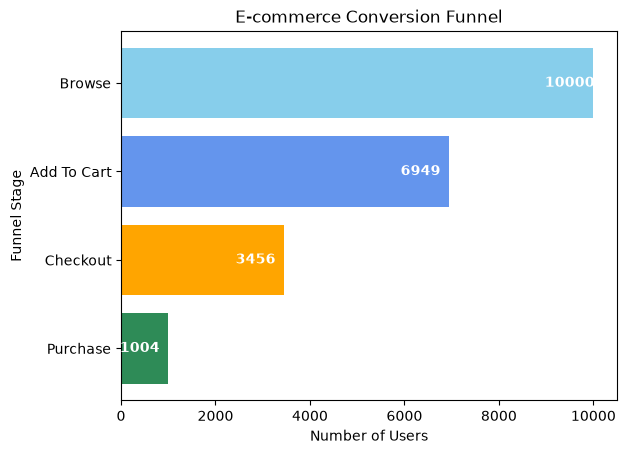

In [85]:
funnel_counts = event_counts.reindex(stages)
bars = plt.barh(stages, funnel_counts,
         color=["skyblue", "cornflowerblue", "orange", "seagreen"])
plt.bar_label(bars, label_type="edge", padding=-35, color="white", fontweight="bold")

plt.title("E-commerce Conversion Funnel")
plt.xlabel("Number of Users")
plt.ylabel("Funnel Stage")
plt.xticks(rotation=0)
plt.gca().invert_yaxis()

plt.show()

**What this graph shows:** The number of users reaching each stage of the shopping journey, from Browse to Purchase.

**Interpretation:** The bars become progressively shorter as users move through the funnel. User count drops steadily from Browse (10,000) to Add to Cart (6,949), Checkout (3,456), and Purchase (1,004). The steepest decline occurs after Checkout, showing that most users drop off before completing payment.


#### Conversion Rate vs Drop-off Rate

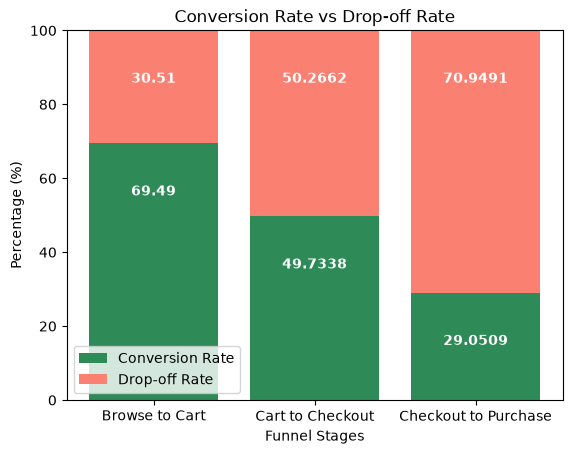

In [86]:
conversion_rate=[]
drop_off=[]
for i in range((len(stages)-1)):
    cur = event_counts[stages[i]]
    nex = event_counts[stages[i+1]]
    conv = (nex/cur)*100
    drop = 100-conv
    conversion_rate.append(conv)
    drop_off.append(drop)
stage_labels=["Browse to Cart","Cart to Checkout","Checkout to Purchase"]
bar1=plt.bar(stage_labels, conversion_rate,
        color="seagreen", label="Conversion Rate")
plt.bar_label(bar1, label_type="edge", padding=-40, color="white", fontweight="bold")
bar2=plt.bar(stage_labels, drop_off,
        bottom=conversion_rate, color="salmon",
        label="Drop-off Rate")
plt.bar_label(bar2, label_type="edge", padding=-40, color="white", fontweight="bold")
plt.title("Conversion Rate vs Drop-off Rate")
plt.xlabel("Funnel Stages")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend()
plt.show()

**What this graph shows:** A stage-by-stage comparison of conversion rates against drop-off rates across the funnel.

**Interpretation:** Browse to Cart has the strongest conversion rate (69.49%), while Checkout to Purchase suffers the highest drop-off rate (70.95%). Reducing friction at the final checkout step offers the biggest opportunity to lift overall sales.


#### Distribution of Unique Users by Marketing Channel

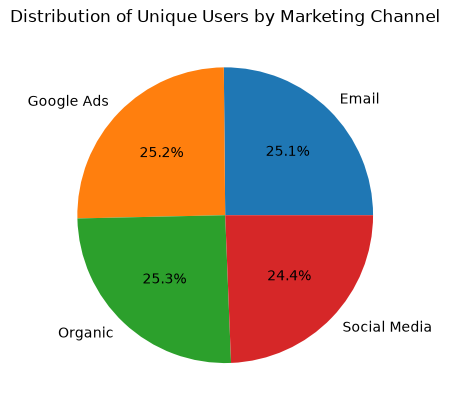

In [88]:
plt.pie(total_users,
        labels=total_users.index,
        autopct="%1.1f%%")
plt.title("Distribution of Unique Users by Marketing Channel")

plt.show()

**What this graph shows**: The percentage share of unique users attributed to each marketing channel.

**Interpretation**: The user distribution is relatively balanced across Google Ads, Email, Organic and Social Media. No single channel dominates audience size.

#### Purchase Conversion Rate by Marketing Channel

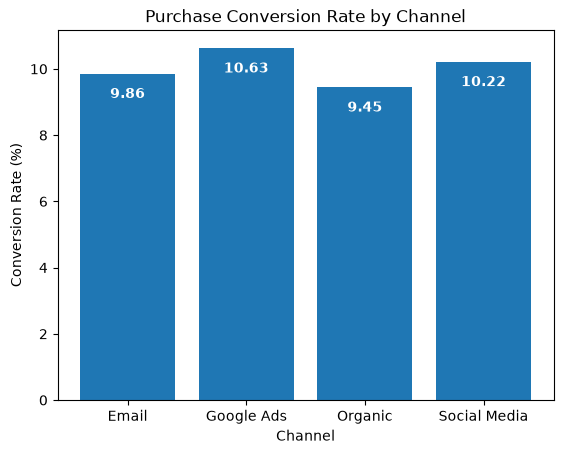

In [89]:
bar3=plt.bar(conversion.index,conversion.values)
plt.bar_label(bar3,label_type="edge", padding=-20, color="white", fontweight="bold")
plt.title("Purchase Conversion Rate by Channel")
plt.xlabel("Channel")
plt.ylabel("Conversion Rate (%)")
plt.show()

**What this graph shows**: The percentage of unique users from each marketing channel who completed a purchase.

**Interpretation**: Google Ads has the highest purchase conversion rate (10.63%), followed by Social Media (10.22%), Email (9.86%) and Organic (9.45%). Google Ads converts its audience most effectively among the four channels in this dataset.

#### Purchase Revenue by Marketing Channel

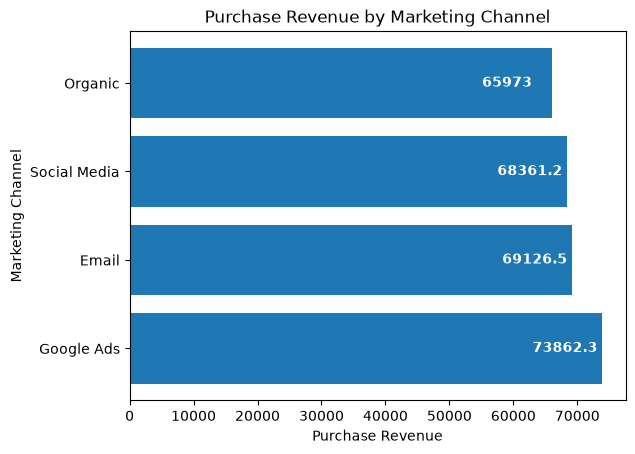

In [90]:
bar4=plt.barh(crevenue.index,crevenue.values)
plt.bar_label(bar4,label_type="edge",padding=-50,color="white",fontweight="bold")
plt.title("Purchase Revenue by Marketing Channel")
plt.xlabel("Purchase Revenue")
plt.ylabel("Marketing Channel")

plt.show()

**What this graph shows**: Total revenue from completed purchases attributed to each marketing channel.

**Interpretation**: Google Ads generates the highest purchase revenue (73,862.32), while Organic generates the lowest (65,973.04). Revenue reflects both the number of purchases and the value of those purchases

#### Purchase Conversion Rate by Device

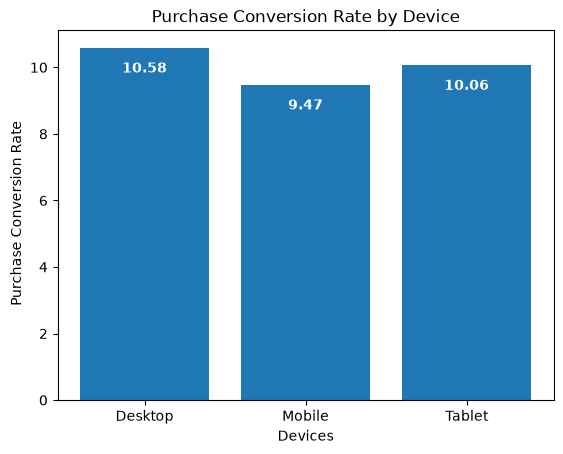

In [91]:
bar4 = plt.bar(c1.index,c1.values)
plt.title("Purchase Conversion Rate by Device")
plt.bar_label(bar4,label_type="edge", padding=-20, color="white", fontweight="bold")
plt.xlabel("Devices")
plt.ylabel(" Purchase Conversion Rate")
plt.show()

**What this graph shows**: Purchase conversion rate for users on Desktop, Tablet and Mobile devices.

**Interpretation**: Desktop has the highest conversion rate (10.58%), followed by Tablet (10.06%) and Mobile (9.47%). Mobile has the lowest conversion rate, making its user journey a useful area for further investigation.

#### Purchase Value Distribution by Device

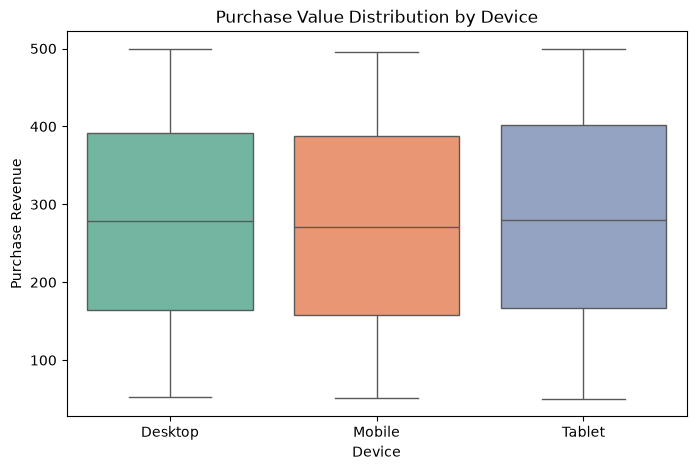

In [92]:
purchase_data = df[df["Event"] == "Purchase"]

plt.figure(figsize=(8, 5))

sns.boxplot(data=purchase_data,
            x="Device",
            y="Revenue",
            hue="Device",
            palette="Set2",
            legend=False)

plt.title("Purchase Value Distribution by Device")
plt.xlabel("Device")
plt.ylabel("Purchase Revenue")
plt.xticks(rotation=0)

plt.show()

**What this graph shows:** The spread and median value of completed purchase amounts across Desktop, Tablet, and Mobile devices.

**Interpretation:** All three devices share nearly the same median order value (around 275) and overall price spread (50 to 500), with no unusual outliers. This indicates that Mobile generates less total revenue solely because fewer mobile users complete checkout, not because they spend less per order.


#### Purchase Conversion Rate by Region 

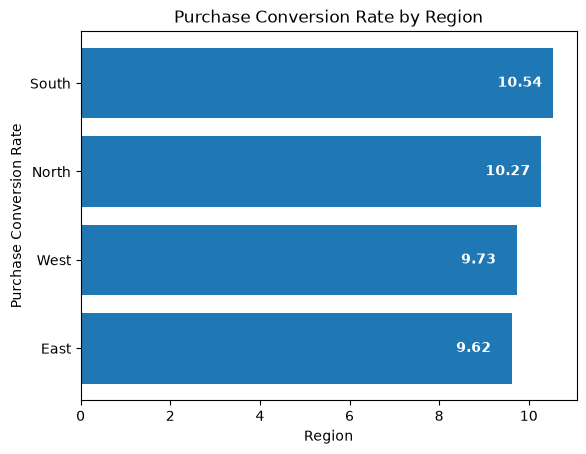

In [93]:
conversion_sort = c2.sort_values()
bar5 = plt.barh(conversion_sort.index,conversion_sort.values)
plt.bar_label(bar5,label_type="edge",padding=-40,color="white",fontweight="bold")
plt.title("Purchase Conversion Rate by Region")
plt.xlabel("Region")
plt.ylabel("Purchase Conversion Rate")
plt.show()

**What this graph shows**:Purchase conversion rate for each region. The horizontal bars make it easier to compare the four regions.

**Interpretation**: South has the highest conversion rate (10.54%), followed by North (10.27%), West (9.73%) and East (9.62%). East has the largest user base but the lowest conversion rate, so its larger audience does not translate into the strongest purchase conversion.

#### Purchase Revenue Distribution by Region

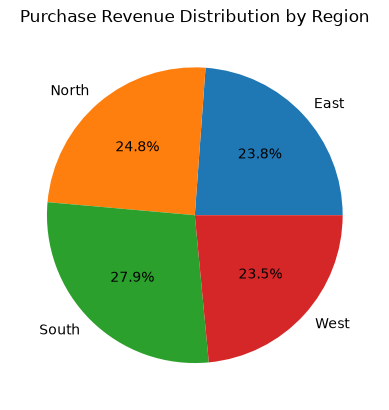

In [94]:
plt.pie(r2,
        labels=r2.index,
        autopct="%1.1f%%")
plt.title("Purchase Revenue Distribution by Region")

plt.show()

**What this graph shows**: Each slice represents a region's share of total purchase revenue.

**Interpretation**: South contributes the largest share of purchase revenue (77,421.45), while West contributes the smallest (65,140.47).

#### Shopping Activity by Product Category

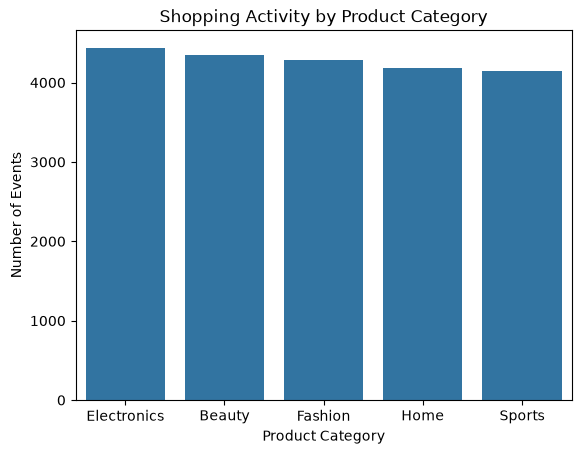

In [95]:
sns.countplot(data=df, x="Product Category", order=category_distribution.index)
plt.title('Shopping Activity by Product Category')
plt.ylabel("Number of Events")
plt.show()

**What this graph shows**: The number of recorded events associated with each product category. It includes all funnel events, not only purchases.

**Interpretation**: Electronics has the highest recorded activity (4,435 events), while Sports has the lowest (4,147). The differences are relatively small, so activity is broadly distributed across the five categories

#### Purchases by Product Category

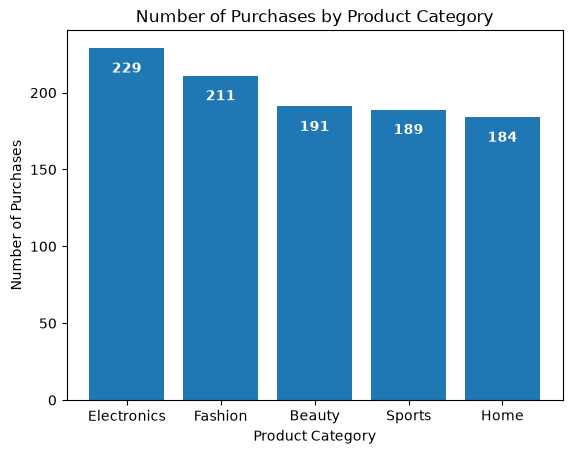

In [96]:
bar5= plt.bar(p3.index,p3.values)
plt.bar_label(bar5,label_type="edge",padding = -20, color="white",fontweight="bold")
plt.title("Number of Purchases by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Purchases")
plt.show()

**What this graph shows**: The number of completed purchases in each product category.

**Interpretation**: Electronics records the most purchases (229, or 22.81% of all purchases).

#### Purchase Revenue by Product Category

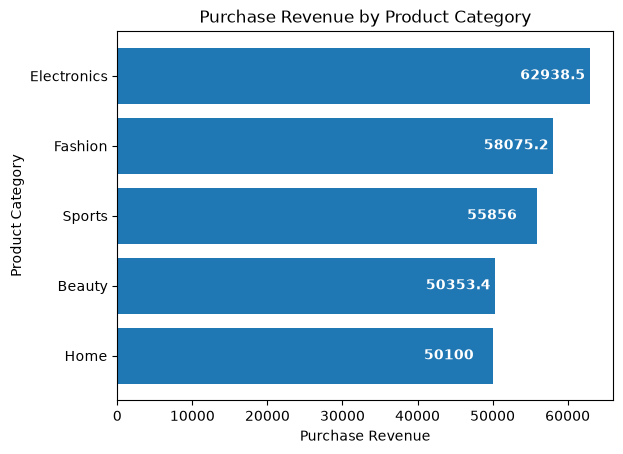

In [97]:
category_revenue = r3.sort_values()
bar5 = plt.barh(category_revenue.index,
                category_revenue.values)
plt.bar_label(bar5, label_type="edge", padding=-50,color="white",fontweight="bold")
plt.title("Purchase Revenue by Product Category")
plt.xlabel("Purchase Revenue")
plt.ylabel("Product Category")
plt.show()

**What this graph shows**: Total revenue generated by completed purchases in each product category.

**Interpretation**: Electronics generates the highest purchase revenue (62,938.46), while Home generates the lowest (50,100.01). Electronics leads in both purchase count and total revenue in this dataset.

#### Purchase Count vs Purchase Revenue by Category

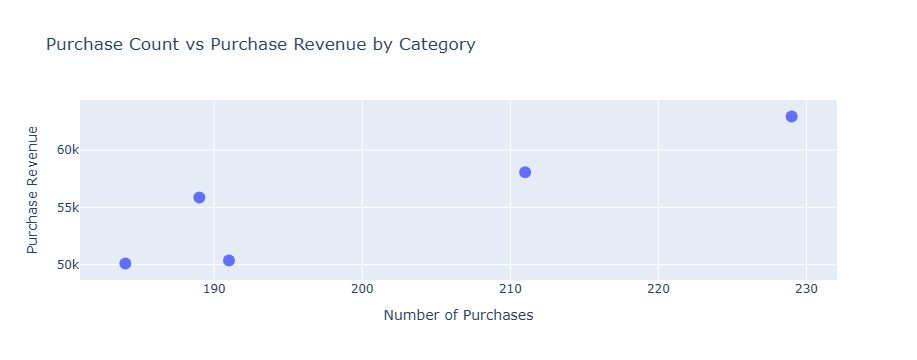

In [98]:
fig = px.scatter(
    x=p3, 
    y=r3.reindex(p3.index), 
    hover_name=p3.index,
    title="Purchase Count vs Purchase Revenue by Category",
    labels={"x": "Number of Purchases", "y": "Purchase Revenue"}
)
fig.update_traces(marker=dict(size=12))  
fig.show()

**What this graph shows:** The relationship between the number of completed purchases and total revenue across product categories.

**Interpretation:** Total revenue generally increases alongside purchase count, placing Electronics at the top right as the strongest overall performer. Sports sits higher on the revenue axis relative to its order count, highlighting higher-value transactions in that category.


#### Distribution of Purchase Values

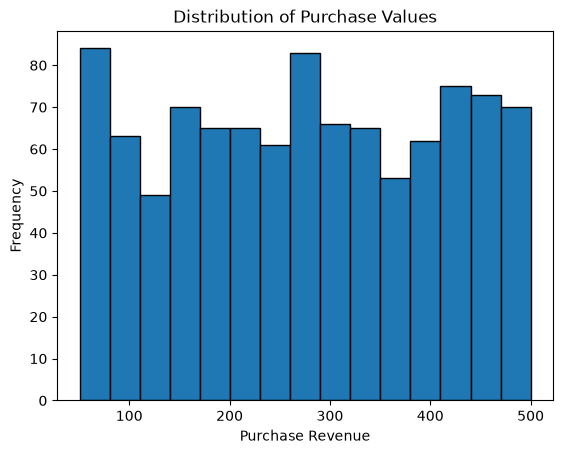

In [100]:
plt.hist(purchase_data["Revenue"],
         bins=15,
         edgecolor="black")
plt.title("Distribution of Purchase Values")
plt.xlabel("Purchase Revenue")
plt.ylabel("Frequency")

plt.show()

**What this graph shows:** The frequency of completed orders across different purchase revenue brackets from 50 to 500.

**Interpretation:** Order values are spread fairly evenly across the entire 50 to 500 price range without clustering around a single price point. Sales rely on a balanced mix of low-, mid-, and high-ticket orders rather than one dominant price tier.


#### Daily Website Activity

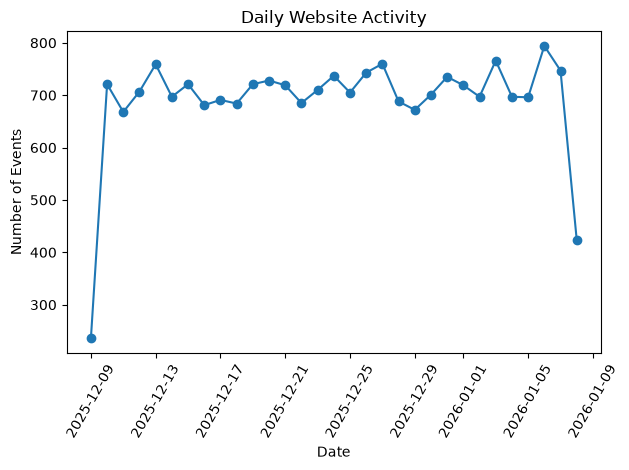

In [161]:
plt.plot(daily_activity.index, daily_activity.values, marker="o")
plt.title("Daily Website Activity")
plt.xlabel("Date")
plt.ylabel("Number of Events")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

**What this graph shows:** Total daily user events recorded on the website across the analysis period.

**Interpretation:** Daily website activity stays steady between 668 and 794 events on all full days, peaking on 6 January 2026 (794 events). The sharp drops on 9 December (236) and 8 January (424) reflect partial-day data coverage at the start and end of the dataset.


#### Daily Purchase Trend

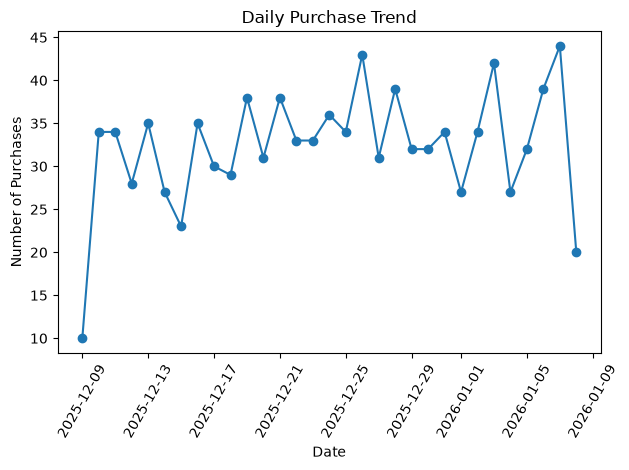

In [162]:
plt.plot(daily_purchases.index.get_level_values("Event Date"),
         daily_purchases.values,
         marker="o")
plt.title("Daily Purchase Trend")
plt.xlabel("Date")
plt.ylabel("Number of Purchases")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

**What this graph shows**: The number of completed purchases recorded on each date.

**Interpretation**: The highest daily purchase count is on 7 January 2026 (44 purchases), followed by 26 December 2025 (43). The trend fluctuates from day to day, showing that purchase volume is not constant throughout the period.

#### Daily Purchase Revenue

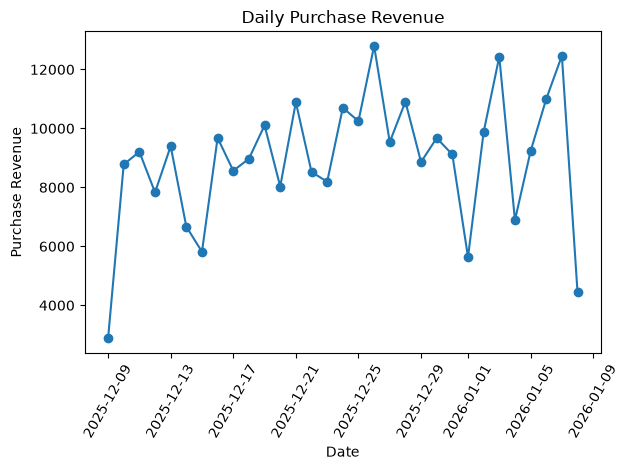

In [163]:
plt.plot(daily_revenue.index.get_level_values("Event Date"),
         daily_revenue.values,
         marker="o")
plt.title("Daily Purchase Revenue")
plt.xlabel("Date")
plt.ylabel("Purchase Revenue")
plt.xticks(rotation=60)

plt.tight_layout()
plt.show()

**What this graph shows** :Total revenue from completed purchases on each date.

**Interpretation**: The highest daily revenue is recorded on 26 December 2025 (12,796.90), followed by 7 January 2026 (12,464.35). The date with the most purchases is not the date with the highest revenue, indicating that average transaction values also affect daily revenue.

#### Hourly Website Activity Across Dates

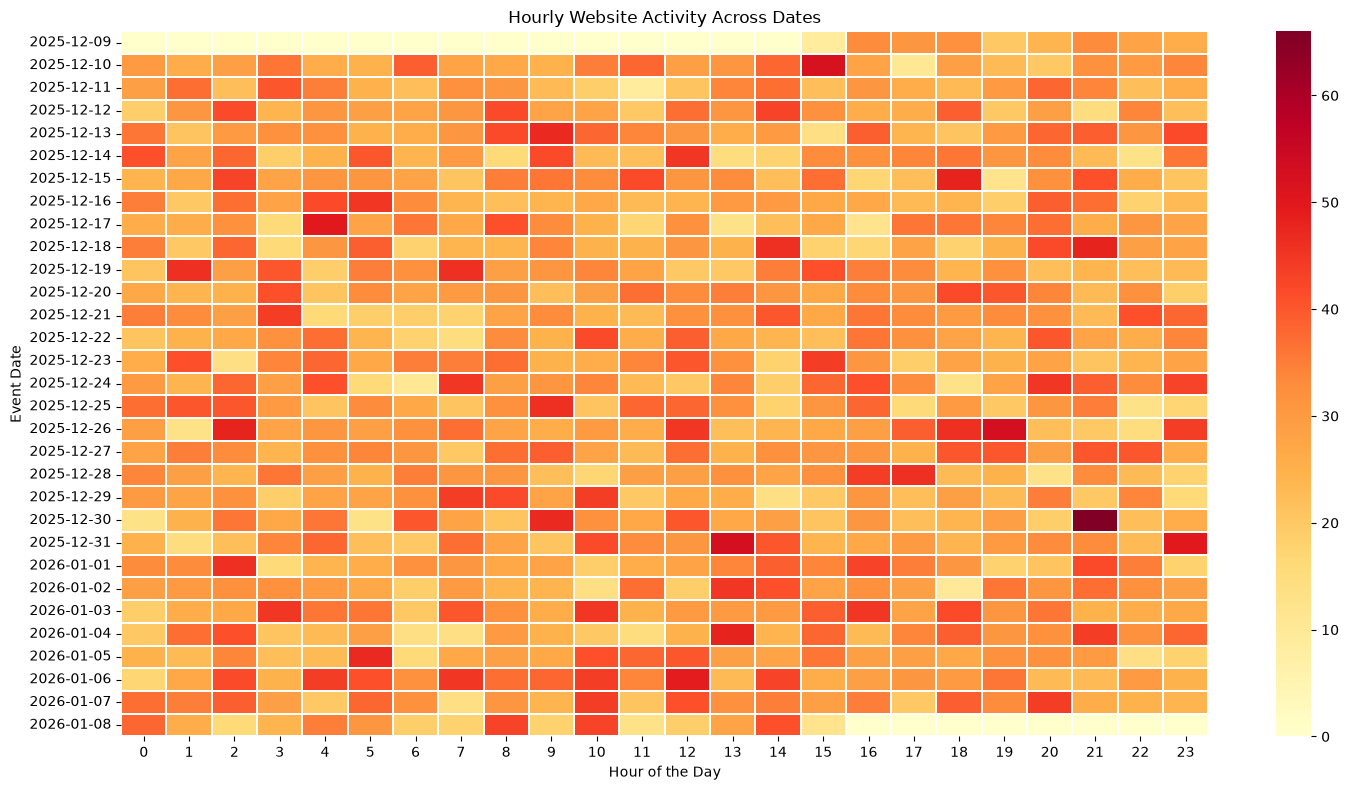

In [164]:
date_hour_activity = pd.crosstab(df["Event Date"], df["Hour"])
plt.figure(figsize=(15, 8))
sns.heatmap(date_hour_activity, cmap="YlOrRd", linewidths=0.3)
plt.title("Hourly Website Activity Across Dates")
plt.xlabel("Hour of the Day")
plt.ylabel("Event Date")
plt.tight_layout()
plt.show()

**What this graph shows:** The intensity of website events for every hour of the day across all dates in the dataset.

**Interpretation:** Website activity occurs around the clock across all dates, with isolated dark-red hotspots such as 30 December at 9:00 PM (66 events) and 26 December at 7:00 PM (53 events). The blank blocks on 9 December and 8 January clearly reflect the partial-day start and end boundaries of the dataset.


# Key Findings & Business Recommendations

#### Key Findings
**Checkout Abandonment is the Primary Bottleneck:** While 69.49% of browsers add items to their cart, **70.95% of users who reach Checkout fail to complete their purchase**.
   
**Mobile Underperforms in Conversion, Not Order Size:** Mobile has the lowest conversion rate (**9.47%**) and lowest total revenue (**84,231.10**),even though mobile buyer spend same meidian amount (275) as Desktop and Tablet users.

**Google Ads & South Region Lead Performance:** **Google Ads** delivers the highest conversion rate (**10.63%**) and revenue (**73,862.32**), while the **South** region leads geographically (**10.54%** conversion, **77,421.45** revenue).

**Electronics Drives Volume; Sports Drives Order Value:** **Electronics** leads in total purchases (**229**) and revenue (**62,938.46**), whereas **Sports** achieves the highest average order value (**295.53**).

#### Actionable Recommendations
**Streamline the Checkout Flow:** Simplify payment steps, offer guest checkout, and display shipping costs upfront to reduce the 70.95% checkout drop-off.

**Optimize Mobile Checkout UX:** Audit mobile page load speeds, form inputs, and mobile wallet options (Apple Pay/Google Pay) to close the conversion gap between Mobile (9.47%) and Desktop (10.58%).

**Reallocate Marketing & Regional Focus:** Scale high-converting **Google Ads** campaigns and investigate why high-traffic segments like **Organic** and the **East** region convert at lower rates.
